# Gusman 2025 source data

This notebook inspects the Dryad release behind the drag-and-drop paper. Two BrainGate2 participants, T11 and T5, each with two 96-channel arrays in the hand knob of the left precentral gyrus, attempting hand gestures and **holding** them.

The motivating problem is that a cursor BCI can point and click but cannot drag, because dragging means keeping one gesture active for seconds while the cursor moves, and a per-timestep classifier drifts or drops out during a sustained attempt. So the release has two tasks: an open-loop **Gesture Hero** task that measures how a gesture representation decays over 1, 2 and 4 second holds, and a closed-loop **drag-and-drop** task driven by a latch decoder.

Three things to look for. The files are MATLAB v7.3, so `h5py` reads them and `scipy.io.loadmat` does not. The 1,344 feature columns are fully attributable, unlike `vargas_2025` from the same group. And the labels are MATLAB `categorical` objects, which decode from the file's own subsystem.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

from neuralshed.datasets.gusman_2025 import utils

## Inventory

Three files, five sessions. `utils.list_sessions` walks all of them, dereferencing the struct arrays in the two files that hold more than one session.

In [2]:
sessions = utils.list_sessions()
print(f"sessions: {len(sessions)}")
print(f"{'label':24s} {'task':14s} {'bins':>8s} {'minutes':>8s} {'blocks':>7s} {'rows':>6s} {'gestures':>9s}")
for ref in sessions:
    table = utils.epochs(ref)
    print(
        f"{ref.label:24s} {ref.task:14s} {utils.n_bins(ref):8d} {utils.duration(ref) / 60:8.1f}"
        f" {len(utils.blocks(ref)):7d} {len(table):6d} {len(utils.gestures(ref)):9d}"
    )
print(f"\ntotal recorded: {sum(utils.duration(r) for r in sessions) / 3600:.1f} hours")

sessions: 5
label                    task               bins  minutes  blocks   rows  gestures


T11_drag_and_drop_s1     drag_and_drop    219677     73.2      11   1557         3


T11_drag_and_drop_s2     drag_and_drop    191957     64.0      11   1672         3
T11_gesture_hero_s1      gesture_hero     166543     55.5      10    420         7
T11_gesture_hero_s2      gesture_hero     166605     55.5      10    421         7
T5_gesture_hero_s1       gesture_hero      70596     23.5       3    180         3

total recorded: 4.5 hours


## The feature axis is attributable

Seven feature types for each of 192 electrodes. The file states the boundaries and the names, so every one of the 1,344 columns maps to a feature type and an electrode. Five of the seven are short-time Fourier bands, which are the first local field potential features in the catalog.

In [3]:
ref = next(r for r in sessions if r.task == utils.TASK_DRAG_DROP)
layout = utils.feature_layout(ref)
print(layout.to_string(index=False))
print()
print(f"arrays: {utils.array_names(ref)}")
print(f"total columns: {utils.N_FEATURES} = {utils.N_CHANNELS} electrodes x {utils.N_FEATURE_TYPES} features")

     feature  start  stop
        ncTX      0   192
  spikePower    192   384
    STFT 0-8    384   576
  STFT 12-16    576   768
  STFT 20-31    768   960
 STFT 39-125    960  1152
STFT 129-250   1152  1344

arrays: ['Lateral', 'Medial']
total columns: 1344 = 192 electrodes x 7 features


Nothing is read eagerly. A session's feature matrix is up to 2.3 GB, so `utils` keeps the file handle open and slices it. Asking for one feature type narrows the read to its 192 rows.

The values are z-scored against a rolling 3 minute window before release, which shows up immediately as a standard deviation near one.

In [4]:
window = slice(0, int(60 * utils.FS))   # one minute
for name in utils.FEATURE_NAMES:
    block = utils.get_features(ref, feature=name, bins=window)
    print(f"{name:14s} {str(block.shape):12s} mean {block.mean():+.3f}  std {block.std():.3f}"
          f"  range [{block.min():+.1f}, {block.max():+.1f}]")

ncTX           (192, 3000)  mean +0.005  std 1.000  range [-1.6, +11.2]
spikePower     (192, 3000)  mean +0.011  std 1.002  range [-3.4, +14.2]


STFT 0-8       (192, 3000)  mean -0.031  std 0.981  range [-2.0, +10.6]
STFT 12-16     (192, 3000)  mean +0.022  std 1.035  range [-2.3, +8.8]


STFT 20-31     (192, 3000)  mean +0.028  std 1.024  range [-2.6, +7.9]
STFT 39-125    (192, 3000)  mean +0.031  std 1.010  range [-3.4, +8.5]


STFT 129-250   (192, 3000)  mean +0.020  std 1.004  range [-3.6, +8.8]


## The categorical labels

`labels`, `cuedGesture`, `cuedDirection`, `trialAttemptType` and `decodedState` are MATLAB `categorical` objects. They appear as `(1, 6)` uint32 references rather than as data, so neither `h5py` nor `scipy` gives you them directly.

They are recoverable from the file's own `#subsystem#/MCOS` group. The reference's fifth element is a 1-based object index, and the payload holds the category names at `2 * index` and the per-element codes at `2 * index + 1`. That is all `utils.read_categorical` does.

In [5]:
for r in sessions:
    print(f"{r.label:24s} {sorted(utils.gestures(r))}")

T11_drag_and_drop_s1     ['Right hand - ok', 'Right hand - power grasp', 'Right index finger - down']


T11_drag_and_drop_s2     ['Right hand - ok', 'Right hand - power grasp', 'Right index finger - down']
T11_gesture_hero_s1      ['Left thumb - down', 'Right hand - key grasp', 'Right hand - ok', 'Right hand - open', 'Right hand - power grasp', 'Right index finger - down', 'Right thumb - down']
T11_gesture_hero_s2      ['Left thumb - down', 'Right hand - key grasp', 'Right hand - ok', 'Right hand - open', 'Right hand - power grasp', 'Right index finger - down', 'Right thumb - down']
T5_gesture_hero_s1       ['Right hand - ok', 'Right hand - power grasp', 'Right index finger - down']


T11 was cued seven gestures in Gesture Hero and only three in drag-and-drop. Note `Left thumb - down` alongside `Right thumb - down`: the seventh class differs from a right-hand class only by which hand, which is the pair worth watching given the arrays are in one hemisphere.

In [6]:
hero = next(r for r in sessions if r.task == utils.TASK_GESTURE_HERO and r.participant == "T11")
table = utils.epochs(hero)
print(table.head(6).to_string(index=False))
print()
print("trials per gesture and cued hold duration:")
print(table.pivot_table(index="label", columns="hold_s", values="start", aggfunc="size", fill_value=0).to_string())

 start  stop  block                     label  hold_s
   448   498      3        Right thumb - down     1.0
   765   965      3         Left thumb - down     4.0
  1232  1282      3 Right index finger - down     1.0
  1548  1598      3         Right hand - open     1.0
  1867  1965      3         Right hand - open     2.0
  2232  2332      3    Right hand - key grasp     2.0

trials per gesture and cued hold duration:
hold_s                     1.0  2.0  4.0
label                                   
Left thumb - down           20   20   20
Right hand - key grasp      20   20   20
Right hand - ok             20   20   20
Right hand - open           20   20   20
Right hand - power grasp    20   20   20
Right index finger - down   20   20   20
Right thumb - down          20   20   20


## The drag-and-drop task table

Rows here are **stages**, not trials, so `trial` groups them and `stage` names the phase. The eleven stage names cover three trial types, and a trial's stage sequence depends on which type it was.

In [7]:
drag = utils.epochs(ref)
print(f"{len(drag)} stages over {drag.trial.nunique()} trials")
print()
print("stages:")
print(drag.stage.value_counts().to_string())
print()
print("trial types:")
print(drag.attempt_type.value_counts().to_string())

1557 stages over 288 trials

stages:
stage
Center Out                             288
Intertrial                             286
Return                                 167
Prepare - Direction + Gesture click    126
Wait click                             126
Prepare - Direction + Gesture          121
Wait Gesture hold                      121
Return & Drag                          121
Hold                                   119
Prepare - Direction                     41
Wait Direction                          41

trial types:
attempt_type
Drag          603
Click         378
Move          290
Intertrial    286


In [8]:
# One trial, start to finish, showing how the stages tile it.
one = drag[drag.trial == 3]
print(one[["trial", "stage", "attempt_type", "label", "direction", "start", "stop"]].to_string(index=False))

 trial               stage attempt_type     label    direction  start  stop
     3 Prepare - Direction         Move no_action        Right   1367  1453
     3          Center Out         Move no_action        Right   1453  1565
     3      Wait Direction         Move no_action No Direction   1565  1643
     3              Return         Move no_action         Left   1643  1754
     3          Intertrial   Intertrial no_action No Direction   1754  1820


Closed-loop status is per stage and per decoder, not a property of a block. The kinematic decoder and the gesture decoder close independently, and `kin_error_attenuation` records how much the cursor was being helped.

In [9]:
print(f"stages with the kinematic decoder closed: {drag.kin_decoder_closed.sum():5d} of {len(drag)}")
print(f"stages with the gesture decoder closed:   {drag.gesture_decoder_closed.sum():5d} of {len(drag)}")
print(f"stages with both closed:                  {(drag.kin_decoder_closed & drag.gesture_decoder_closed).sum():5d}")
print()
print("cursor error attenuation:")
print(drag.kin_error_attenuation.value_counts().sort_index().to_string())

stages with the kinematic decoder closed:  1405 of 1557
stages with the gesture decoder closed:     949 of 1557
stages with both closed:                    949

cursor error attenuation:
kin_error_attenuation
0.0    1253
0.3     152
0.5     152


## The online decoder's own output

Drag-and-drop sessions carry the latch decoder's decision for every 20 ms bin, over the same four states the task cues. That makes it a stream rather than a per-trial value, and it is what the paper's error-free-epoch numbers are computed from.

In [10]:
decoded = utils.decoded_state(ref)
print(f"decoded state: {decoded.shape} over {sorted(set(decoded))}")
print()
counts = Counter(decoded)
for state, n in counts.most_common():
    print(f"   {state:28s} {n:7d} bins  {n / len(decoded):5.1%}")

decoded state: (219677,) over ['Right hand - ok', 'Right hand - power grasp', 'Right index finger - down', 'no_action']

   no_action                     180665 bins  82.2%
   Right hand - ok                14177 bins   6.5%
   Right index finger - down      12913 bins   5.9%
   Right hand - power grasp       11922 bins   5.4%


## Gesture selectivity decays with hold duration

This is the measurement the whole paper rests on, and it is visible without any decoding.

The window has to be controlled to see it. Averaging over the whole hold confounds duration with how much data is being averaged, and a 4 s hold then looks *more* selective simply because it is less noisy. Taking a fixed 500 ms window at the **end** of each hold holds the data volume constant so that only the elapsed time since gesture onset varies.

T11_gesture_hero_s1    1s: 42.7%  2s: 35.4%  4s: 32.8%


T5_gesture_hero_s1     1s: 55.7%  2s: 27.6%  4s: 26.0%


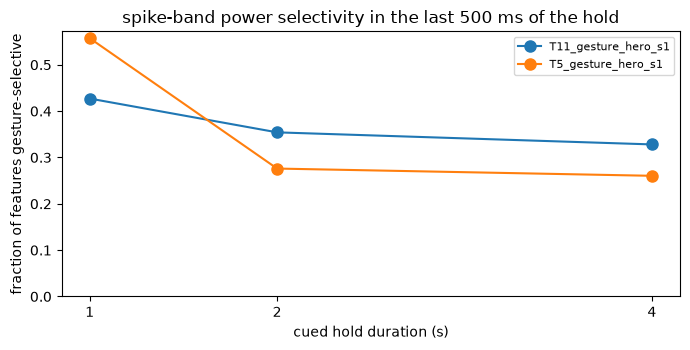

In [11]:
from scipy import stats

# Fixed 500 ms window at the end of each hold, so every duration uses the same amount of
# data. Selectivity is the fraction of features whose response differs across gestures.
WINDOW = int(0.5 * utils.FS)

def selectivity(ref, feature="spikePower"):
    table = utils.epochs(ref)
    block = utils.get_features(ref, feature=feature)
    out = []
    for hold in sorted(table.hold_s.unique()):
        sub = table[table.hold_s == hold]
        ends = np.array([row.start + int(hold * utils.FS) for row in sub.itertuples()])
        response = np.array([block[:, end - WINDOW : end].mean(axis=1) for end in ends])
        labels = sub.label.to_numpy()
        groups = [response[labels == name] for name in sorted(set(labels))]
        p = np.array([
            stats.kruskal(*[g[:, i] for g in groups]).pvalue
            for i in range(response.shape[1])
        ])
        out.append((hold, float((p < 0.05).mean())))
    return out


fig, ax = plt.subplots(figsize=(7, 3.6))
for ref in [r for r in sessions if r.task == utils.TASK_GESTURE_HERO and r.session == 1]:
    scores = selectivity(ref)
    holds = [h for h, _ in scores]
    ax.plot(holds, [f for _, f in scores], "o-", ms=8, label=ref.label)
    print(f"{ref.label:22s} " + "  ".join(f"{h:.0f}s: {f:5.1%}" for h, f in scores))
ax.set(xlabel="cued hold duration (s)", ylabel="fraction of features gesture-selective",
       title="spike-band power selectivity in the last 500 ms of the hold", xticks=holds)
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
plt.tight_layout()

## Summary

- Three MATLAB v7.3 files, five sessions, 4.5 hours: two Gesture Hero sessions from T11, one from T5, and two drag-and-drop sessions from T11.
- Blocks are concatenated onto one continuous 20 ms grid per session, so this is a recording rather than a bag of clips, and task tables index into it with bin ranges.
- 1,344 columns, seven feature types across 192 electrodes, every one attributable. Five are local field potential bands, a first for the catalog.
- All features are z-scored against a rolling 3 minute window, so the values are dimensionless.
- The MATLAB `categorical` labels decode from the file's own subsystem with `h5py` alone.
- Drag-and-drop rows are stages rather than trials, and closed-loop status is recorded per stage and per decoder.
- Gesture separability falls as the hold gets longer, which is the observation the latch decoder exists to work around.